# 8. Comparatif final et recommandations

Ce notebook répond aux trois dernières questions du sujet :
1. **Analyse comparative** des modèles et méthodes appliqués (supervisés : notebooks 3 et 5 ; semi-supervisés : notebooks 6 et 7), avec des métriques justifiées ;
2. **Conclusion** : quelle approche est la plus appropriée pour prédire la qualité de soudure ;
3. **Recommandations** pour obtenir une bonne soudure.

Il ne ré-entraîne **aucun** modèle : il relit les fichiers enregistrés dans `1. Données/05_reporting/` (prédictions du test, scores de validation croisée, modèles finaux) et les met côte à côte.

**Les deux cibles retenues par l'équipe**
- `Charpy conforme` (notebook 2) : 1 si la soudure atteint **47 J à −40 °C** (EN ISO 2560-A), avec interpolation de la température de transition entre 28 J et 100 J ; c'est un critère de **ténacité** (résistance à la rupture fragile à froid).
- `Profil de résistance` (notebooks 4 et 5) : 1 = résistance **élevée**, 0 = **modérée**, obtenu par ACP + K-means sur les quatre propriétés de traction (limite d'élasticité, résistance à la traction, allongement, striction).

In [1]:
import json
import warnings
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.inspection import partial_dependence
from sklearn.metrics import balanced_accuracy_score, f1_score, roc_auc_score

from utils_pipeline import WeldImputer, feature_engineering, QUALITY_VARIABLES

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")

RANDOM_STATE = 42
N_BOOT = 1000            # rééchantillonnages bootstrap (par publication) pour les IC du test
ID_COL = "Weld ID"
CSV = dict(sep=";", encoding="utf-8-sig")

P_DONNEES = Path("..") / "1. Données"
P_REP = P_DONNEES / "05_reporting"
P_SORTIE = P_REP / "comparatif_final"
P_SORTIE.mkdir(parents=True, exist_ok=True)
P_FIG = Path("..") / "3. Résultats" / "figures"
P_FIG.mkdir(parents=True, exist_ok=True)

def lire(chemin):
    return pd.read_csv(chemin, **CSV)

def savefig(nom):
    plt.savefig(P_FIG / f"final_{nom}.png", dpi=150, bbox_inches="tight")

# Où sont rangés les résultats de chaque cible
CIBLES = {
    "Charpy conforme": dict(
        sup=P_REP / "prediction_Charpy conforme" / "Charpy_conforme",
        ssl=P_REP / "semi_supervise" / "charpy",
        notebooks="3 (supervisé) et 6 (semi-supervisé)"),
    "Profil de résistance": dict(
        sup=P_REP / "profil_resistance",
        ssl=P_REP / "semi_supervise" / "profil_resistance",
        notebooks="5 (supervisé) et 7 (semi-supervisé)"),
}
METHODES_SUP = {"A_sans_selection": "Supervisé A (toutes les variables)",
                "B_avec_selection": "Supervisé B (sélection forward)"}

## 1. Comparatif final des modèles

### 1.1 Métriques utilisées

On note $TP, TN, FP, FN$ les vrais/faux positifs/négatifs, la classe 1 étant « conforme » (Charpy) ou « résistance élevée » (profil).

| Métrique | Formule | Pourquoi |
|---|---|---|
| **Accuracy pondérée** (*balanced accuracy*) | $\frac{1}{2}\left(\frac{TP}{TP+FN} + \frac{TN}{TN+FP}\right)$ | Moyenne des rappels des deux classes : vaut **0,5 pour un modèle qui prédit toujours la même classe**, quel que soit le déséquilibre. **Métrique principale** du comparatif. |
| F1 (classe 1) | $\frac{2\,TP}{2\,TP+FP+FN}$ | Métrique de sélection des notebooks 3 et 5. Pour Charpy (86 % de conformes), elle est **gonflée** : prédire « conforme » partout donne déjà F1 ≈ 0,91. |
| F1 classe 0 | $\frac{2\,TN}{2\,TN+FN+FP}$ | Capacité à repérer les soudures **non conformes** / à résistance modérée : pour Charpy, c'est l'erreur la plus coûteuse (accepter une soudure fragile). |
| ROC AUC | $P(\hat s(x^+) > \hat s(x^-))$ | Qualité du classement par la probabilité prédite, indépendamment du seuil 0,5. |

**Pourquoi l'accuracy pondérée comme métrique principale ?** Les deux cibles sont déséquilibrées (86 % de conformes pour Charpy, 35 % de résistance élevée pour le profil). L'accuracy simple et le F1 de la classe majoritaire récompensent un modèle qui ignore la classe rare ; l'accuracy pondérée donne le même poids aux deux classes (Brodersen et al., 2010).

**Intervalles de confiance** : bootstrap **par publication** (on tire des publications avec remise, pas des soudures), car les soudures d'une même étude ne sont pas indépendantes. C'est cohérent avec les découpages groupés par publication (`StratifiedGroupKFold`) utilisés dans tous les notebooks.

### 1.2 Tous les modèles sur le même jeu de test

Les notebooks semi-supervisés (6 et 7) ont **réutilisé exactement le même découpage train/test** que les notebooks supervisés (3 et 5). On peut donc comparer toutes les méthodes **sur les mêmes soudures de test**, avec les mêmes métriques recalculées ici à partir des prédictions enregistrées.

In [2]:
def metriques(y, pred, proba):
    y, pred = np.asarray(y).astype(int), np.asarray(pred).astype(int)
    return {"Accuracy pondérée": balanced_accuracy_score(y, pred),
            "F1 (classe 1)": f1_score(y, pred, zero_division=0),
            "F1 classe 0": f1_score(1 - y, 1 - pred, zero_division=0),
            "ROC AUC": roc_auc_score(y, proba) if len(np.unique(y)) > 1 and np.std(proba) > 0 else 0.5}

def ic_bootstrap_groupes(y, pred, groupes, n_boot=N_BOOT, seed=RANDOM_STATE):
    '''IC95 de l'accuracy pondérée par bootstrap des publications.'''
    rng = np.random.default_rng(seed)
    y, pred, groupes = np.asarray(y), np.asarray(pred), np.asarray(groupes)
    uniques = np.unique(groupes)
    idx_par_groupe = {g: np.flatnonzero(groupes == g) for g in uniques}
    scores = []
    for _ in range(n_boot):
        idx = np.concatenate([idx_par_groupe[g] for g in rng.choice(uniques, len(uniques), replace=True)])
        if len(np.unique(y[idx])) == 2:
            scores.append(balanced_accuracy_score(y[idx], pred[idx]))
    return np.percentile(scores, [2.5, 97.5])

lignes, preds_test = [], {}
for cible, c in CIBLES.items():
    # --- supervisé (notebooks 3 et 5) : méthodes A et B
    for meth, libelle in METHODES_SUP.items():
        t = lire(c["sup"] / meth / "test_predictions.csv")
        nom = json.load(open(c["sup"] / meth / "modele_retenu.json", encoding="utf-8"))["modele_retenu"]
        preds_test[(cible, f"{libelle} : {nom}")] = (t["reel"], t["predit"], t["proba"], t["groupe"])
    # --- référence naïve : la classe majoritaire du train, prédite partout
    t = lire(c["sup"] / "A_sans_selection" / "test_predictions.csv")
    split = lire(c["sup"] / "split_train_test.csv")
    col = split.columns[-1]
    majo = int(split.loc[split["jeu"] == "Train", col].mean() >= 0.5)
    preds_test[(cible, "Référence naïve : classe majoritaire")] = (t["reel"], np.full(len(t), majo),
                                                                   np.full(len(t), 0.5), t["groupe"])
    # --- semi-supervisé (notebooks 6 et 7) ; on écarte le modèle de l'équipe ré-entraîné dans ces notebooks
    t = lire(c["ssl"] / "test_predictions.csv")
    for meth, g in t.groupby("methode"):
        if "retenu par l'équipe" in meth:
            continue
        preds_test[(cible, f"Semi-supervisé : {meth}")] = (g["y"], g["y_pred"], g["proba"], g["groupe"])

for (cible, modele), (y, pred, proba, grp) in preds_test.items():
    bas, haut = ic_bootstrap_groupes(y, pred, grp)
    lignes.append({"cible": cible, "modèle": modele, "n test": len(y), "publications test": grp.nunique(),
                   **metriques(y, pred, proba), "IC95 bas": bas, "IC95 haut": haut})

comparatif_test = pd.DataFrame(lignes)
for cible in CIBLES:
    print(f"\n=== {cible} : jeu de test commun ===")
    display(comparatif_test[comparatif_test["cible"] == cible].drop(columns="cible")
            .sort_values("Accuracy pondérée", ascending=False).set_index("modèle").round(3))


=== Charpy conforme : jeu de test commun ===


,n test,publications test,Accuracy pondérée,F1 (classe 1),F1 classe 0,ROC AUC,IC95 bas,IC95 haut
modèle,,,,,,,,
Supervisé A (toutes les variables) : XGBoost (défaut),108,6,0.824,0.968,0.786,0.804,0.500,1.000
Semi-supervisé : Self-training équilibré,108,6,0.818,0.963,0.759,0.828,0.500,1.000
Semi-supervisé : Self-training classique,108,6,0.765,0.958,0.692,0.718,0.500,1.000
Semi-supervisé : Label spreading,108,6,0.743,0.935,0.600,0.662,0.278,1.000
Semi-supervisé : CEM semi-supervisé,108,6,0.582,0.653,0.306,0.612,0.259,1.000
Supervisé B (sélection forward) : XGBoost,108,6,0.531,0.896,0.167,0.917,0.136,0.812
Référence naïve : classe majoritaire,108,6,0.500,0.915,0.000,0.500,0.500,0.500



=== Profil de résistance : jeu de test commun ===


,n test,publications test,Accuracy pondérée,F1 (classe 1),F1 classe 0,ROC AUC,IC95 bas,IC95 haut
modèle,,,,,,,,
Semi-supervisé : Label spreading,127,23,0.852,0.827,0.927,0.961,0.654,0.950
Supervisé B (sélection forward) : Arbre,127,23,0.846,0.784,0.855,0.907,0.705,0.919
Supervisé A (toutes les variables) : Arbre,127,23,0.846,0.784,0.855,0.907,0.705,0.919
Semi-supervisé : Self-training équilibré,127,23,0.846,0.784,0.855,0.907,0.705,0.919
Semi-supervisé : Self-training classique,127,23,0.846,0.784,0.855,0.907,0.705,0.919
Semi-supervisé : CEM semi-supervisé,127,23,0.771,0.703,0.878,0.919,0.525,0.893
Référence naïve : classe majoritaire,127,23,0.500,0.000,0.790,0.500,0.500,0.500


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True)
for ax, cible in zip(axes, CIBLES):
    t = comparatif_test[comparatif_test["cible"] == cible].sort_values("Accuracy pondérée")
    couleurs = ["#888888" if m.startswith("Référence") else "#1f77b4" if m.startswith("Supervisé") else "#ff7f0e"
                for m in t["modèle"]]
    y = np.arange(len(t))
    ax.errorbar(t["Accuracy pondérée"], y,
                xerr=[t["Accuracy pondérée"] - t["IC95 bas"], t["IC95 haut"] - t["Accuracy pondérée"]],
                fmt="none", ecolor="lightgrey", elinewidth=3)
    ax.scatter(t["Accuracy pondérée"], y, c=couleurs, s=70, zorder=3)
    ax.set_yticks(y, t["modèle"].str.replace(" : ", " :\n", n=1), fontsize=8)
    ax.axvline(0.5, ls="--", c="grey", lw=1)
    ax.set(title=cible, xlabel="Accuracy pondérée (test, IC95 par publication)", xlim=(0.3, 1.0))
axes[0].scatter([], [], c="#1f77b4", label="supervisé"); axes[0].scatter([], [], c="#ff7f0e", label="semi-supervisé")
axes[0].scatter([], [], c="#888888", label="référence naïve"); axes[0].legend(loc="lower right", fontsize=8)
plt.suptitle("Comparatif final sur le jeu de test commun", y=1.02)
plt.tight_layout()
savefig("comparatif_test")
plt.show()

<Figure size 1400x500 with 2 Axes>

### 1.3 La validation croisée, qui a servi à choisir

Le test (108 soudures issues de **6 publications** seulement pour Charpy, 127 soudures et 23 publications pour le profil) est **petit** : les intervalles ci-dessus sont larges. Les **choix** de modèles ont donc été faits en validation croisée groupée par publication, sur le train uniquement :
- notebooks 3 et 5 : 100 répétitions d'une validation croisée à 5 plis sur de nouveaux découpages pour départager les finalistes ;
- notebooks 6 et 7 : validation croisée imbriquée (5 plis externes × 3 plis internes) pour régler puis évaluer les méthodes semi-supervisées, avec un gain **apparié** par rapport au modèle de l'équipe.

Les deux protocoles n'utilisent pas exactement les mêmes plis : on compare surtout les **ordres de grandeur** et, pour le semi-supervisé, le **gain apparié** (mêmes plis pour les deux modèles), qui est la comparaison la plus fiable.

In [4]:
lignes = []
for cible, c in CIBLES.items():
    for meth, libelle in METHODES_SUP.items():
        js = json.load(open(c["sup"] / meth / "modele_retenu.json", encoding="utf-8"))
        res = lire(c["sup"] / meth / "finalistes_resume.csv").set_index("modele")
        col_acc = [k for k in res.columns if k.startswith("Accuracy")][0]
        col_f1 = [k for k in res.columns if k.startswith("F1")][0]
        lignes.append({"cible": cible, "modèle": f"{libelle} : {js['modele_retenu']}",
                       "Accuracy pondérée (CV)": res.loc[js["modele_retenu"], col_acc],
                       "F1 (CV)": res.loc[js["modele_retenu"], col_f1],
                       "gain apparié vs équipe": np.nan, "IC95 du gain": ""})
    js = json.load(open(c["ssl"] / "modele_retenu_ssl.json", encoding="utf-8"))
    for meth, s in js["score_cv_imbriquee"].items():
        if "retenu par l'équipe" in meth:
            continue
        g = js["gains_cv_imbriquee"].get(meth, {})
        lignes.append({"cible": cible, "modèle": f"Semi-supervisé : {meth}",
                       "Accuracy pondérée (CV)": s.get("Accuracy_ponderee"), "F1 (CV)": s.get("F1"),
                       "gain apparié vs équipe": g.get("gain", np.nan),
                       "IC95 du gain": f"[{g['IC95_bas']:+.3f} ; {g['IC95_haut']:+.3f}]" if g else ""})
comparatif_cv = pd.DataFrame(lignes)
for cible in CIBLES:
    print(f"\n=== {cible} : validation croisée (train uniquement) ===")
    display(comparatif_cv[comparatif_cv["cible"] == cible].drop(columns="cible").set_index("modèle").round(3))
    js = json.load(open(CIBLES[cible]["ssl"] / "modele_retenu_ssl.json", encoding="utf-8"))
    print("Recommandation enregistrée par le notebook semi-supervisé :", js["recommandation"])


=== Charpy conforme : validation croisée (train uniquement) ===


,Accuracy pondérée (CV),F1 (CV),gain apparié vs équipe,IC95 du gain
modèle,,,,
Supervisé A (toutes les variables) : XGBoost (défaut),0.770,0.937,NaN,
Supervisé B (sélection forward) : XGBoost,0.874,0.960,NaN,
Semi-supervisé : Self-training classique,0.829,0.947,0.102,[-0.056 ; +0.223]
Semi-supervisé : Self-training équilibré,0.823,0.936,0.096,[-0.113 ; +0.227]
Semi-supervisé : Label spreading,0.747,0.927,0.020,[-0.222 ; +0.212]
Semi-supervisé : CEM semi-supervisé,0.850,0.900,0.123,[-0.133 ; +0.297]


Recommandation enregistrée par le notebook semi-supervisé : XGBoost (défaut) supervisé (notebook 3) : aucun gain semi-supervisé significatif en CV, et le semi-supervisé retenu est moins bon sur le test

=== Profil de résistance : validation croisée (train uniquement) ===


,Accuracy pondérée (CV),F1 (CV),gain apparié vs équipe,IC95 du gain
modèle,,,,
Supervisé A (toutes les variables) : Arbre,0.848,0.797,NaN,
Supervisé B (sélection forward) : Arbre,0.847,0.797,NaN,
Semi-supervisé : Self-training classique,0.847,0.800,0.000,[+0.000 ; +0.000]
Semi-supervisé : Self-training équilibré,0.847,0.800,0.000,[+0.000 ; +0.000]
Semi-supervisé : Label spreading,0.573,0.336,-0.274,[-0.346 ; -0.191]
Semi-supervisé : CEM semi-supervisé,0.735,0.658,-0.112,[-0.212 ; -0.030]


Recommandation enregistrée par le notebook semi-supervisé : Arbre supervisé (notebook 5) : aucun gain semi-supervisé significatif en CV


### 1.4 Analyse du comparatif

*(Chiffres de notre exécution.)*

**`Charpy conforme`**
- **Le XGBoost de l'équipe (méthode A, toutes les variables) est le meilleur sur le test** : accuracy pondérée 0,82, et surtout le meilleur **F1 classe 0** (0,79) : c'est lui qui repère le mieux les soudures non conformes. Le self-training équilibré le suit de près (0,82), sans le dépasser.
- **La méthode B (sélection forward) sur-apprend** : c'est la meilleure en validation croisée (0,87) mais elle s'effondre sur le test (0,53, à peine mieux que la référence naïve ; F1 classe 0 = 0,17). Les variables ont été choisies en regardant les scores de validation croisée, qui deviennent donc trop optimistes : c'est le biais de sélection décrit par Ambroise & McLachlan (2002). Ici, il est d'autant plus fort que les non-conformes sont rares.
- **Le semi-supervisé n'apporte pas de gain établi** : en validation croisée imbriquée, les gains appariés vont de +0,02 à +0,12, mais tous leurs IC95 contiennent 0. La méthode que la règle fixée à l'avance retenait (CEM) chute à 0,58 sur le test.
- **Le test ne permet pas de départager les meilleurs modèles** : il ne contient que 6 publications et 17 non-conformes, qui viennent de 3 études seulement. Le bootstrap par publication donne donc des IC95 très larges ([0,5 ; 1,0]). C'est pourquoi toutes les décisions ont été prises en validation croisée, et le test n'a servi qu'à vérifier.

**`Profil de résistance`**
- **Presque toutes les méthodes font le même score** (accuracy pondérée 0,846) : l'arbre de l'équipe, l'arbre de la méthode B (la sélection forward garde les deux mêmes variables) et les deux self-trainings font **exactement les mêmes prédictions**.
- Le label spreading est très légèrement meilleur sur le test (0,852), mais il est **nettement moins bon en validation croisée** (0,57 ; gain apparié −0,27, IC95 [−0,35 ; −0,19]). Sur 127 soudures, cet écart de test n'est pas interprétable.
- Le CEM est moins bon partout (0,77 sur le test ; −0,11 en validation croisée, IC95 qui exclut 0).

**Les deux cibles** sont prédites bien au-dessus de la référence naïve (0,5). Les modèles apprennent donc une vraie relation entre la composition ou le procédé et la qualité.

## 2. L'approche la plus appropriée

**Pour les deux cibles, on retient le modèle supervisé de l'équipe, appris sur toutes les variables (méthode A) :**

| Cible | Modèle retenu | Accuracy pondérée test | Pourquoi |
|---|---|---|---|
| `Charpy conforme` | XGBoost (paramètres par défaut) | 0,82 | Meilleur sur le test, meilleure détection des non-conformes ; aucune méthode semi-supervisée ne fait significativement mieux en validation croisée. |
| `Profil de résistance` | Arbre de décision de profondeur 2 | 0,85 | À égalité avec les meilleures méthodes, le plus simple, et **lisible** : deux variables et trois règles (section 3.2). |

**Ce qu'on ne retient pas, et pourquoi**
- **La sélection forward (méthode B)** : elle n'apporte rien pour le profil (même arbre) et sur-apprend pour Charpy. Avec aussi peu de soudures non conformes, choisir les variables sur les mêmes données que celles qui servent à évaluer est risqué.
- **Le semi-supervisé** : ses hypothèses ne sont que partiellement vérifiées (beaucoup de soudures non étiquetées décrivent des familles d'aciers sans aucune étiquette), et il n'améliore pas significativement les modèles de l'équipe lorsque toutes les étiquettes sont utilisées. Il n'a donné un **gain significatif que lorsque les étiquettes sont rares** (self-training, profil de résistance avec 25 % des étiquettes, notebook 7). Il serait donc utile pour une **nouvelle propriété peu mesurée**, pas pour ces deux cibles.

**La vraie limite n'est pas le modèle mais les données** : les soudures d'une même publication se ressemblent beaucoup, et généraliser à une **étude jamais vue** reste difficile (variance très forte d'un pli à l'autre). Plus de publications, en particulier avec des soudures non conformes, améliorerait davantage les résultats qu'un modèle plus complexe.

## 3. Recommandations pour obtenir une bonne soudure

### 3.1 Démarche

Un modèle prédictif ne dit pas directement **comment** obtenir une bonne soudure. Pour en tirer des recommandations, on croise trois lectures, du plus « modèle » au plus « données brutes » :
1. **Importance par permutation** (notebooks 3 et 5) : quelles variables le modèle retenu **utilise** réellement ;
2. **Dépendance partielle** (Friedman, 2001) : comment la probabilité prédite évolue quand on fait varier **une** variable, les autres restant celles des soudures du train. Elle donne le **sens** de l'effet appris par le modèle ;
3. **Taux observés dans les données** par tranche de la variable, avec le nombre de soudures **et de publications** concernées.

**Précaution** : ces liens sont des **corrélations**, pas des effets causaux. Dans cette base, une tranche de composition correspond souvent à une seule famille d'aciers (par exemple les aciers Cr-Mo, testés par quelques études seulement). Une recommandation n'est donc retenue que si elle est **cohérente entre les trois lectures** et avec la **métallurgie du soudage**, et si elle repose sur **plusieurs publications**.

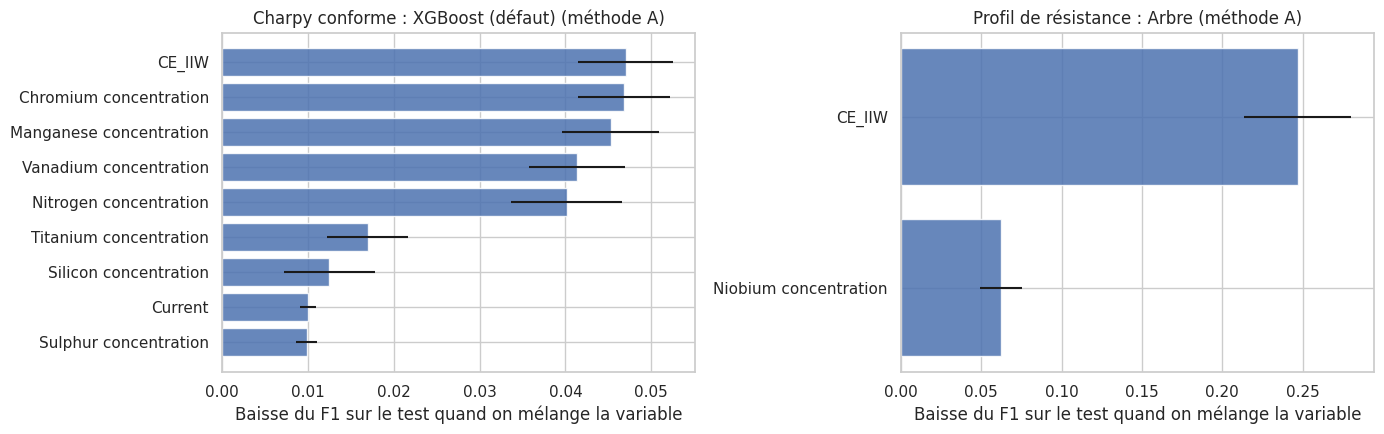

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, (cible, c) in zip(axes, CIBLES.items()):
    js = json.load(open(c["sup"] / "A_sans_selection" / "modele_retenu.json", encoding="utf-8"))
    imp = lire(c["sup"] / "A_sans_selection" / "importance_permutation_retenu.csv")
    imp = imp[imp["importance moyenne"] > 0].sort_values("importance moyenne")
    ax.barh(imp["variable"], imp["importance moyenne"], xerr=imp["écart-type"], alpha=.85)
    ax.set(title=f"{cible} : {js['modele_retenu']} (méthode A)",
           xlabel="Baisse du F1 sur le test quand on mélange la variable")
plt.tight_layout()
savefig("importance_variables")
plt.show()

### 3.2 Profil de résistance : les règles de l'arbre de l'équipe

Le modèle retenu pour le profil de résistance est un **arbre de profondeur 2** : ses règles se lisent directement, dans les unités d'origine (les variables numériques ne sont pas transformées avant l'arbre).

In [6]:
arbre_pipe = joblib.load(CIBLES["Profil de résistance"]["sup"] / "A_sans_selection" / "modele_final.joblib")
prep, arbre = arbre_pipe.steps[0][1], arbre_pipe.steps[-1][1]
noms = [n.split("__", 1)[-1] for n in prep.get_feature_names_out()]
t = arbre.tree_

def decrire(noeud=0, conditions=()):
    if t.children_left[noeud] == -1:
        v = t.value[noeud][0] / t.value[noeud][0].sum()
        return [{"règle": " et ".join(conditions) or "toutes", "soudures du train": int(t.n_node_samples[noeud]),
                 "part de résistance élevée": round(float(v[1]), 2)}]
    var, seuil = noms[t.feature[noeud]], t.threshold[noeud]
    return (decrire(t.children_left[noeud], conditions + (f"{var} ≤ {seuil:.4g}",)) +
            decrire(t.children_right[noeud], conditions + (f"{var} > {seuil:.4g}",)))

regles_arbre = pd.DataFrame(decrire())
display(regles_arbre)
print("Centres des deux profils (notebook 4) :")
display(lire(CIBLES["Profil de résistance"]["sup"] / "centres_profils.csv").round(0))

,règle,soudures du train,part de résistance élevée
0,CE_IIW ≤ 0.3662 et Niobium concentration ≤ 0.0135,314,0.12
1,CE_IIW ≤ 0.3662 et Niobium concentration > 0.0135,29,0.70
2,CE_IIW > 0.3662 et CE_IIW ≤ 0.4448,77,0.75
3,CE_IIW > 0.3662 et CE_IIW > 0.4448,103,0.97


Centres des deux profils (notebook 4) :


,classe,Yield strength,Ultimate tensile strength,Elongation,Reduction of Area
0,0,455.0,541.0,29.0,76.0
1,1,587.0,677.0,22.0,66.0


### 3.3 Sens des effets appris : dépendance partielle

Pour chaque cible, on recharge le **modèle final de l'équipe** (méthode A) et on reconstruit ses entrées comme dans les notebooks 3 et 5 (mêmes lignes, même découpage, même imputation apprise sur le train, même carbone équivalent). On vérifie d'abord que le modèle rechargé **reproduit exactement** les prédictions du test enregistrées.

In [7]:
df = lire(P_DONNEES / "02_intermediate" / "welddb_processed_vf.csv")
corresp = lire(P_DONNEES / "02_intermediate" / "correspondance_between_names_units_vf.csv")
TARGETS = list(set(corresp.loc[corresp["Role"] == "Quality indicator", "Feature"]) & set(df.columns))
MASQUES = {"Charpy conforme": df["Charpy conforme"].notna(),
           "Profil de résistance": df[QUALITY_VARIABLES].notna().all(axis=1)}

entrees = {}
for cible, c in CIBLES.items():
    d = df[MASQUES[cible]].reset_index(drop=True)
    X = d.drop(columns=TARGETS + [ID_COL])
    split = lire(c["sup"] / "split_train_test.csv")
    train = split.loc[split["jeu"] == "Train", "position_dans_d"].to_numpy()
    imp = WeldImputer().fit(X.iloc[train])                 # même imputation que l'équipe : apprise sur le train
    X_fe = feature_engineering(imp.transform(X))
    modele = joblib.load(c["sup"] / "A_sans_selection" / "modele_final.joblib")
    t = lire(c["sup"] / "A_sans_selection" / "test_predictions.csv")
    identiques = (modele.predict(X_fe.iloc[t["position_dans_d"]]) == t["predit"].to_numpy()).mean()
    print(f"{cible} : {identiques:.0%} des prédictions du test reproduites")
    entrees[cible] = (modele, X_fe.iloc[train])

Charpy conforme : 100% des prédictions du test reproduites
Profil de résistance : 100% des prédictions du test reproduites


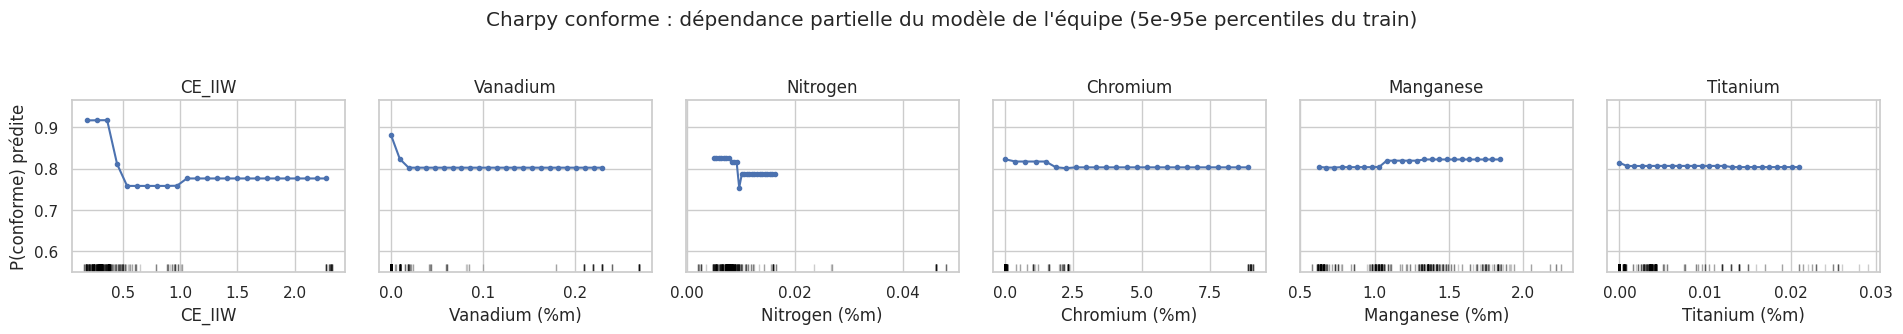

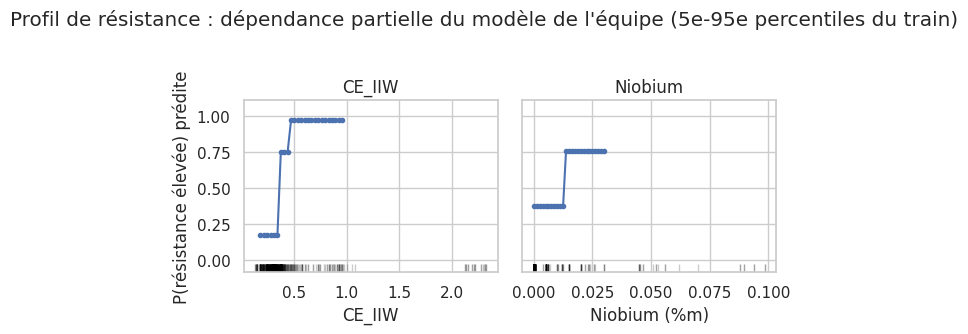

In [8]:
VARIABLES_PDP = {
    "Charpy conforme": ["CE_IIW", "Vanadium concentration", "Nitrogen concentration",
                        "Chromium concentration", "Manganese concentration", "Titanium concentration"],
    "Profil de résistance": ["CE_IIW", "Niobium concentration"],
}
LIBELLE_Y = {"Charpy conforme": "P(conforme) prédite", "Profil de résistance": "P(résistance élevée) prédite"}

pdp = []
for cible, variables in VARIABLES_PDP.items():
    modele, X_tr = entrees[cible]
    fig, axes = plt.subplots(1, len(variables), figsize=(3.2 * len(variables), 3.2), sharey=True, squeeze=False)
    for ax, v in zip(axes[0], variables):
        r = partial_dependence(modele, X_tr, [v], kind="average", grid_resolution=25, percentiles=(0.05, 0.95))
        grille, moy = r["grid_values"][0], r["average"][0]
        ax.plot(grille, moy, marker="o", ms=3)
        ax.set(xlabel=v.replace(" concentration", " (%m)"), title=v.replace(" concentration", ""))
        sns.rugplot(X_tr[v], ax=ax, height=0.05, alpha=0.2, color="black")
        pdp.append(pd.DataFrame({"cible": cible, "variable": v, "valeur": grille, "proba moyenne prédite": moy}))
    axes[0][0].set_ylabel(LIBELLE_Y[cible])
    plt.suptitle(f"{cible} : dépendance partielle du modèle de l'équipe (5e-95e percentiles du train)", y=1.04)
    plt.tight_layout()
    savefig(f"dependance_partielle_{'charpy' if cible.startswith('Charpy') else 'profil'}")
    plt.show()
pdp = pd.concat(pdp, ignore_index=True)

**Lecture des dépendances partielles**

- **`Charpy conforme` (XGBoost)** : le **carbone équivalent** a l'effet le plus net. La probabilité d'être conforme est de 0,92 tant que `CE_IIW` ≲ 0,40, puis tombe à 0,76 au-delà d'environ 0,5. Le **vanadium** vient ensuite : 0,88 sans vanadium, 0,80 dès 0,02 %. L'**azote** fait baisser la probabilité au-delà d'environ 0,010 % (0,83 → 0,79), et le **chrome** très légèrement au-delà de 1,5 %. Le **manganèse** a un léger effet positif entre 1,0 et 1,8 %, et le titane un effet négligeable. Les amplitudes restent modestes (moins de 0,15 de probabilité) : le XGBoost répartit l'information sur plusieurs variables corrélées et en interaction.
- **`Profil de résistance` (arbre)** : la courbe est en marches d'escalier, puisque c'est un arbre. La probabilité d'une résistance élevée vaut 0,18 pour `CE_IIW` ≤ 0,366, 0,76 entre 0,366 et 0,445, et 0,97 au-delà. Un **niobium** supérieur à 0,0135 % la fait passer de 0,38 à 0,76 en moyenne.

**Interprétation métallurgique** : le carbone équivalent mesure la **trempabilité** de l'acier. Plus il est élevé, plus le métal fondu forme des constituants durs (bainite, martensite), ce qui augmente la résistance mais réduit la ténacité. Le vanadium, le niobium et l'azote durcissent par **précipitation** (carbures et nitrures), avec le même effet : plus résistant, moins tenace.

### 3.4 Le compromis résistance / ténacité selon le carbone équivalent

Le carbone équivalent `CE_IIW` est la variable la plus importante **pour les deux cibles**. On regarde dans les données brutes (toutes les soudures étiquetées, train et test) comment évoluent, par tranche de `CE_IIW` :
- la part de soudures **conformes Charpy** (ténacité) ;
- la part de soudures à **résistance élevée**.

Pour le profil, on applique la règle ACP + K-means apprise par l'équipe sur le train (`labeler.joblib`) à toutes les soudures dont les quatre propriétés de traction sont connues.

,variable,tranche,n Charpy,publications Charpy,% conformes,n profil,publications profil,% résistance élevée
0,CE_IIW,"(0.0, 0.3]",213,16,99.0,236,31,5.0
1,CE_IIW,"(0.3, 0.35]",149,15,96.0,151,32,16.0
2,CE_IIW,"(0.35, 0.4]",77,19,96.0,100,27,43.0
3,CE_IIW,"(0.4, 0.45]",14,9,64.0,32,13,72.0
4,CE_IIW,"(0.45, 0.5]",19,7,63.0,23,9,96.0
5,CE_IIW,"(0.5, 0.6]",17,7,41.0,24,13,92.0
6,CE_IIW,"(0.6, 0.8]",10,3,10.0,18,9,94.0
7,CE_IIW,"(0.8, 3.0]",70,5,11.0,66,8,97.0


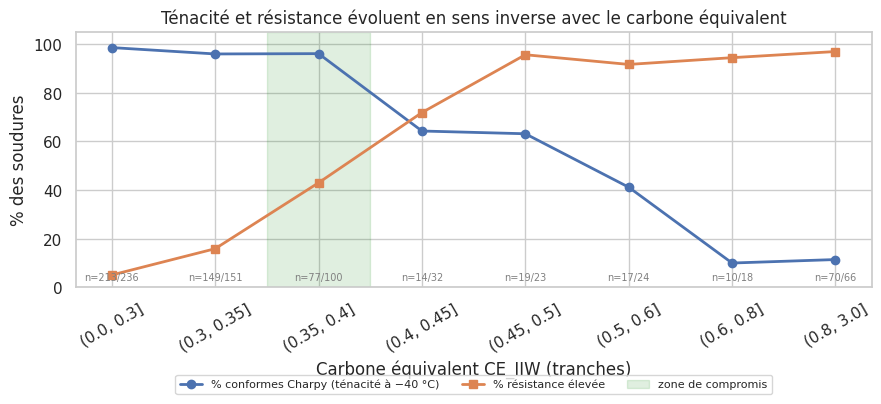

In [9]:
X_tout = df.drop(columns=TARGETS + [ID_COL])
X_tout = feature_engineering(WeldImputer().fit(X_tout).transform(X_tout))   # descriptif : pas d'évaluation ici
labeler = joblib.load(CIBLES["Profil de résistance"]["sup"] / "labeler.joblib")
profil = pd.Series(np.nan, index=df.index)
masque_p = MASQUES["Profil de résistance"]
profil[masque_p] = labeler.predict(df[masque_p])

obs = pd.DataFrame({"CE_IIW": X_tout["CE_IIW"], "Charpy conforme": df["Charpy conforme"],
                    "Résistance élevée": profil, ID_COL: df[ID_COL]})
for v in ["Manganese concentration", "Vanadium concentration", "Niobium concentration", "Nitrogen concentration", "Titanium concentration",
          "Oxygen concentration", "Nickel concentration", "Chromium concentration", "Heat input"]:
    obs[v] = X_tout[v]

def taux_par_tranche(var, bornes):
    t = obs.assign(tranche=pd.cut(obs[var], bornes))
    out = []
    for tr, g in t.groupby("tranche", observed=True):
        gc, gp = g[g["Charpy conforme"].notna()], g[g["Résistance élevée"].notna()]
        out.append({"variable": var, "tranche": str(tr),
                    "n Charpy": len(gc), "publications Charpy": gc[ID_COL].nunique(),
                    "% conformes": 100 * gc["Charpy conforme"].mean() if len(gc) else np.nan,
                    "n profil": len(gp), "publications profil": gp[ID_COL].nunique(),
                    "% résistance élevée": 100 * gp["Résistance élevée"].mean() if len(gp) else np.nan})
    return pd.DataFrame(out)

BORNES_CE = [0, 0.30, 0.35, 0.40, 0.45, 0.50, 0.60, 0.80, 3]
taux_ce = taux_par_tranche("CE_IIW", BORNES_CE)
display(taux_ce.round(0))

fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(taux_ce))
ax.plot(x, taux_ce["% conformes"], marker="o", lw=2, label="% conformes Charpy (ténacité à −40 °C)")
ax.plot(x, taux_ce["% résistance élevée"], marker="s", lw=2, label="% résistance élevée")
ax.axvspan(1.5, 2.5, color="green", alpha=0.12, label="zone de compromis")
for i, r in taux_ce.iterrows():
    ax.annotate(f"n={r['n Charpy']}/{r['n profil']}", (i, 3), ha="center", fontsize=7, color="grey")
ax.set_xticks(x, taux_ce["tranche"], rotation=30)
ax.set(xlabel="Carbone équivalent CE_IIW (tranches)", ylabel="% des soudures", ylim=(0, 105),
       title="Ténacité et résistance évoluent en sens inverse avec le carbone équivalent")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.32), ncol=3, fontsize=8)
plt.tight_layout()
savefig("compromis_carbone_equivalent")
plt.show()

**Lecture : un compromis net entre résistance et ténacité**

- Jusqu'à `CE_IIW` = 0,40, **au moins 96 % des soudures sont conformes Charpy** (439 soudures, une quinzaine à une vingtaine de publications par tranche).
- Au-delà de 0,40, la conformité chute : environ 64 % entre 0,40 et 0,50, 41 % entre 0,50 et 0,60, environ 10 % au-delà.
- La résistance élevée suit l'évolution inverse : 5 % sous 0,30, 43 % entre 0,35 et 0,40, 72 % entre 0,40 et 0,45, plus de 90 % au-delà de 0,45.
- **La zone 0,35-0,40 est le meilleur compromis** : la conformité Charpy reste à 96 % et une soudure sur deux environ atteint déjà une résistance élevée. C'est cohérent avec le seuil de l'arbre (0,366) et avec la chute de la dépendance partielle de Charpy entre 0,40 et 0,45 : **les trois lectures concordent**.

**Précaution** : les carbones équivalents très élevés (> 0,6) correspondent surtout à des aciers au chrome-molybdène, étudiés par peu de publications (3 à 5). Ces aciers sont conçus pour la tenue à chaud, pas pour la ténacité à −40 °C. Leur faible conformité confirme la tendance, mais ne doit pas être sur-interprétée.

### 3.5 Les autres variables de composition et de procédé

Même lecture pour les variables qui ressortent de l'importance par permutation ou de la métallurgie du soudage. **Les colonnes « publications » sont essentielles** : une tranche observée dans une ou deux études seulement ne permet pas de conclure.

In [10]:
BORNES = {
    "Manganese concentration": [0, 0.8, 1.2, 1.5, 1.8, 3],
    "Vanadium concentration": [-0.1, 0, 0.02, 0.05, 1],
    "Niobium concentration": [-0.1, 0, 0.01, 0.02, 1],
    "Nitrogen concentration": [0, 0.006, 0.008, 0.010, 0.012, 0.1],
    "Titanium concentration": [-0.1, 0, 0.01, 0.03, 1],
    "Oxygen concentration": [0, 0.02, 0.03, 0.04, 0.05, 1],
    "Nickel concentration": [-0.1, 0.5, 1, 2, 3, 20],
    "Chromium concentration": [-0.1, 0.1, 0.5, 1.5, 3, 20],
    "Heat input": [0, 1, 1.5, 2, 3, 10],
}
taux_autres = pd.concat([taux_par_tranche(v, b) for v, b in BORNES.items()], ignore_index=True)
display(taux_autres.set_index(["variable", "tranche"]).round(0))

n Charpy  publications Charpy  \
variable                tranche                                         
Manganese concentration (0.0, 0.8]           127                   10   
                        (0.8, 1.2]           125                   16   
                        (1.2, 1.5]           227                   27   
                        (1.5, 1.8]            52                   12   
                        (1.8, 3.0]            38                    8   
Vanadium concentration  (-0.1, 0.0]          238                   12   
                        (0.0, 0.02]          253                   20   
                        (0.02, 0.05]          13                    1   
                        (0.05, 1.0]           65                    5   
Niobium concentration   (-0.1, 0.0]          290                   16   
                        (0.0, 0.01]          218                   16   
                        (0.01, 0.02]          21                    3   
                        (0.02, 1.0]           40                    3   
Nitrogen concentration  (0.0, 0.006]         121                    7   
                        (0.006, 0.008]       250                   19   
                        (0.008, 0.01]        129                   21   
                        (0.01, 0.012]         16                    7   
                        (0.012, 0.1]          53                    5   
Titanium concentration  (-0.1, 0.0]          169                   13   
                        (0.0, 0.01]          304                   21   
                        (0.01, 0.03]          78                    5   
                        (0.03, 1.0]           18                    1   
Oxygen concentration    (0.0, 0.02]           14                    2   
                        (0.02, 0.03]          26                    6   
                        (0.03, 0.04]         106                   11   
                        (0.04, 0.05]         367                   31   
                        (0.05, 1.0]           56                    5   
Nickel concentration    (-0.1, 0.5]          529                   31   
                        (0.5, 1.0]             8                    3   
                        (1.0, 2.0]            12                    3   
                        (2.0, 3.0]            11                    3   
                        (3.0, 20.0]            9                    3   
Chromium concentration  (-0.1, 0.1]          464                   29   
                        (0.1, 0.5]             2                    1   
                        (0.5, 1.5]            15                    4   
                        (1.5, 3.0]            49                    5   
                        (3.0, 20.0]           39                    2   
Heat input              (0.0, 1.0]           490                   28   
                        (1.0, 1.5]             6                    1   
                        (1.5, 2.0]            12                    2   
                        (2.0, 3.0]            28                    5   
                        (3.0, 10.0]           33                    3   

                                        % conformes  n profil  \
variable                tranche                                 
Manganese concentration (0.0, 0.8]             83.0       134   
                        (0.8, 1.2]             58.0       167   
                        (1.2, 1.5]             94.0       230   
                        (1.5, 1.8]             96.0        80   
                        (1.8, 3.0]             55.0        39   
Vanadium concentration  (-0.1, 0.0]            95.0       334   
                        (0.0, 0.02]            83.0       235   
                        (0.02, 0.05]          100.0        19   
                        (0.05, 1.0]            23.0        62   
Niobium concentration   (-0.1, 0.0]            84.0       371   
                        (0.0, 0.01]            

**Lecture**

- **Manganèse** : la conformité est maximale entre **1,2 et 1,8 %** (94 à 96 %, 27 et 12 publications). Elle est plus faible en dessous (58 % entre 0,8 et 1,2 %) et au-dessus de 1,8 % (55 %). Cet optimum est classique pour les métaux fondus C-Mn (Evans & Bailey, 1997), et cohérent avec l'effet légèrement positif vu en dépendance partielle.
- **Vanadium et niobium** : au-delà de 0,05 % de vanadium ou de 0,01 % de niobium, la conformité tombe à 12-38 %, tandis que la part de résistance élevée monte à 52-84 %. C'est l'effet durcissant des micro-alliages, mais il repose sur **peu de publications** (3 à 6).
- **Azote** : la conformité est maximale entre **0,006 et 0,008 %** (98 %, 19 publications) et s'effondre au-delà de 0,012 % (9 %, 5 publications). L'azote libre fragilise le métal fondu.
- **Oxygène et titane** : la conformité dépasse 90 % pour **0,03-0,05 % d'oxygène (300-500 ppm)** (11 et 31 publications) et pour **un peu de titane (jusqu'à 0,01 %)** (91 % contre 62 % sans titane, 21 et 13 publications). C'est cohérent avec la **ferrite aciculaire**, une microstructure tenace qui germe sur les inclusions d'oxydes de titane (Bhadeshia & Svensson, 1993). Attention : l'oxygène et l'azote manquants ont été imputés par la médiane du procédé, ce qui gonfle artificiellement la tranche 0,04-0,05 %.
- **Nickel** : 100 % de conformes au-delà de 2 % de nickel, ce qui est cohérent avec l'effet connu du nickel sur la ténacité à froid. Mais cela ne repose que sur 20 soudures et 3 publications.
- **Chrome** : au-delà de 1,5 %, la conformité tombe (3-27 %) et la résistance est presque toujours élevée (91-100 %). Ce sont les aciers chrome-molybdène, d'où le même effet que le carbone équivalent.
- **Énergie de soudage** : 89 % de conformes pour un apport de **1 kJ/mm ou moins** (28 publications), contre 32-39 % au-dessus. C'est cohérent avec une microstructure plus fine à faible apport, mais les forts apports viennent de peu de publications et d'autres procédés (arc submergé, fil fourré) : l'effet est **confondu avec le procédé**.

### 3.6 Recommandations

Les niveaux de confiance sont donnés selon la concordance entre modèle, dépendance partielle, données brutes et littérature, et selon le nombre de publications concernées.

**A. Pour une soudure tenace à froid (47 J à −40 °C)**
1. **Garder un carbone équivalent `CE_IIW` ≤ 0,40.** Au moins 96 % de soudures conformes en dessous, chute rapide au-dessus. *Confiance élevée* : première variable des deux modèles, trois lectures concordantes, de nombreuses publications.
2. **Viser un manganèse entre 1,2 et 1,8 %.** *Confiance moyenne à élevée* : optimum observé sur de nombreuses publications, cohérent avec la littérature.
3. **Limiter l'azote à environ 0,010 % (idéalement 0,006-0,008 %)** et **limiter les micro-alliages durcissants** : vanadium ≲ 0,02-0,05 %, niobium ≲ 0,01 %. *Confiance moyenne* : effet visible dans le modèle et dans les données, mais les fortes teneurs viennent de peu d'études.
4. **Viser 300 à 500 ppm d'oxygène avec une petite addition de titane** (≲ 0,01-0,03 %), pour favoriser la ferrite aciculaire. *Confiance moyenne* : cohérent avec la littérature et avec de nombreuses publications, mais le modèle de l'équipe utilise peu ces variables et l'oxygène a souvent été imputé.
5. **Préférer un apport d'énergie modéré (≈ 1 kJ/mm)**, et éventuellement un peu de nickel (2-3 %) si une forte ténacité est exigée. *Confiance faible* : effets confondus avec le procédé ou limités à trois publications.

**B. Pour une résistance élevée**
- Le levier principal est le **carbone équivalent** : 75 % de résistances élevées au-delà de 0,366, et 97 % au-delà de 0,445 (règles de l'arbre). À carbone équivalent faible, un **niobium > 0,0135 %** suffit souvent (70 %).

**C. Pour avoir les deux à la fois**
- Viser un **`CE_IIW` d'environ 0,37 à 0,40**, avec un manganèse de 1,2 à 1,8 % et peu de vanadium, de niobium et d'azote. Pour gagner en résistance, il vaut mieux augmenter légèrement le carbone équivalent dans cette fenêtre que d'ajouter des micro-alliages, qui font chuter la ténacité.

**Limites**
- Ce sont des **associations** observées dans une base issue de publications, pas des expériences contrôlées. Chaque tranche de composition correspond souvent à une famille d'aciers et à quelques études (nombre de publications indiqué dans les tableaux).
- Le test de `Charpy conforme` ne compte que 6 publications : les performances annoncées sont incertaines.
- La définition de `Charpy conforme` (47 J à −40 °C) est un choix de l'équipe. Une autre exigence (−20 °C, −60 °C) déplacerait les seuils.
- Les seuils proposés sont des **ordres de grandeur** à confirmer par des essais, pas des spécifications.

## 4. Sauvegarde (`05_reporting/comparatif_final/`)

- `comparatif_test.csv` : toutes les méthodes sur le jeu de test commun (accuracy pondérée et son IC95 par publication, F1, F1 classe 0, ROC AUC) ;
- `comparatif_cv.csv` : scores de validation croisée et gains appariés du semi-supervisé ;
- `regles_arbre_profil.csv` : règles de l'arbre retenu pour le profil de résistance ;
- `dependance_partielle.csv` : courbes de dépendance partielle ;
- `taux_par_tranche.csv` : taux de conformité et de résistance élevée par tranche de variable (avec effectifs et nombre de publications) ;
- figures `3. Résultats/figures/final_*.png`.

In [11]:
comparatif_test.to_csv(P_SORTIE / "comparatif_test.csv", index=False, **CSV)
comparatif_cv.to_csv(P_SORTIE / "comparatif_cv.csv", index=False, **CSV)
regles_arbre.to_csv(P_SORTIE / "regles_arbre_profil.csv", index=False, **CSV)
pdp.to_csv(P_SORTIE / "dependance_partielle.csv", index=False, **CSV)
pd.concat([taux_ce, taux_autres], ignore_index=True).to_csv(P_SORTIE / "taux_par_tranche.csv", index=False, **CSV)
print(sorted(p.name for p in P_SORTIE.iterdir()))

['comparatif_cv.csv', 'comparatif_test.csv', 'dependance_partielle.csv', 'regles_arbre_profil.csv', 'taux_par_tranche.csv']


## Références

**Métriques et évaluation**
- K. H. Brodersen, C. S. Ong, K. E. Stephan, J. M. Buhmann (2010). *The balanced accuracy and its posterior distribution*. ICPR 2010, 3121-3124. [doi:10.1109/ICPR.2010.764](https://doi.org/10.1109/ICPR.2010.764)
- T. Saito, M. Rehmsmeier (2015). *The precision-recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets*. PLoS ONE, 10(3). [doi:10.1371/journal.pone.0118432](https://doi.org/10.1371/journal.pone.0118432)
- B. Efron, R. J. Tibshirani (1993). *An Introduction to the Bootstrap*. Chapman & Hall.

**Interprétation des modèles**
- J. H. Friedman (2001). *Greedy function approximation: a gradient boosting machine*. Annals of Statistics, 29(5), 1189-1232 — dépendance partielle. [doi:10.1214/aos/1013203451](https://doi.org/10.1214/aos/1013203451)
- L. Breiman (2001). *Random forests*. Machine Learning, 45, 5-32 — importance par permutation.
- C. Molnar (2022). [*Interpretable Machine Learning*](https://christophm.github.io/interpretable-ml-book/), 2e éd.

**Métallurgie du soudage**
- H. K. D. H. Bhadeshia, L.-E. Svensson (1993). *Modelling the evolution of microstructure in steel weld metal*. In *Mathematical Modelling of Weld Phenomena*, Institute of Materials, 109-182.
- G. M. Evans, N. Bailey (1997). *Metallurgy of Basic Weld Metal*. Abington Publishing — effets de Mn, Ni, Ti, O, N, V, Nb sur la ténacité des métaux fondus C-Mn (base de nombreuses publications de la base de données).
- T. Cool, H. K. D. H. Bhadeshia, D. J. C. MacKay (1997). *The yield and ultimate tensile strength of steel welds*. Materials Science and Engineering A, 223, 186-200.
- International Institute of Welding (IIW) — carbone équivalent $CE_{IIW} = C + \frac{Mn}{6} + \frac{Cr+Mo+V}{5} + \frac{Ni+Cu}{15}$.
- [Base de données utilisée : *Weld metal database*, Phase Transformations group, University of Cambridge](https://www.phasetrans.msm.cam.ac.uk/map/data/materials/welddb-b.html)